本 notebook 是 [M02.5 最优化](../notes/05-optimization.qmd) 的实例讲解。

1. 1. 曲率控制稳定步长
2. 2. SGD 的噪声底
3. 3. Adam、AdamW 与 L-BFGS
4. 4. KKT 的四类条件

在 VS Code 中选择仓库 `.venv` 内核，逐单元运行；运行结果随文件保存。示例使用固定随机种子和合成数据。

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib_inline.backend_inline import set_matplotlib_formats
from scipy.optimize import minimize

from semiai.plotting import BLUE, GRAY, ORANGE, use_style

use_style()
set_matplotlib_formats("svg")
rng = np.random.default_rng(42)

## 1. 曲率控制稳定步长

在有两个曲率尺度的凸二次函数上观察 GD 与 Momentum 的轨迹。比较的是相同目标和初始点，不是对所有问题的优化器排名。

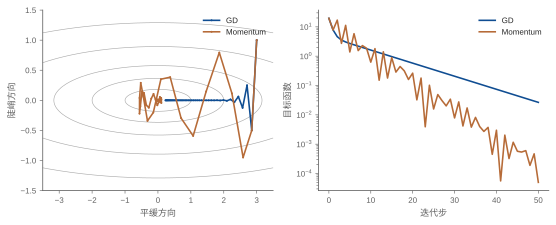

Hessian 特征值: [ 1. 30.] GD 稳定上界: 0.06666666666666667
GD 最终参数: [2.30834926e-01 8.88178420e-16] Momentum 最终参数: [-0.0098718  -0.00030087]


In [2]:
A = np.diag([1.0, 30.0])


def path(eta, beta=0.0):
    w = np.array([3.0, 1.0])
    v = np.zeros(2)
    history = [w.copy()]
    for _ in range(50):
        v = beta * v + A @ w
        w = w - eta * v
        history.append(w.copy())
    return np.array(history)


fig, axes = plt.subplots(1, 2, figsize=(7.8, 3.2))
xx, yy = np.meshgrid(np.linspace(-3.5, 3.5, 150), np.linspace(-1.5, 1.5, 150))
axes[0].contour(
    xx, yy, (xx**2 + 30 * yy**2) / 2, levels=[0.5, 2, 5, 12, 25], colors=GRAY, linewidths=0.6
)
for eta, beta, name, color in [(0.05, 0.0, "GD", BLUE), (0.05, 0.8, "Momentum", ORANGE)]:
    trajectory = path(eta, beta)
    axes[0].plot(*trajectory.T, ".-", ms=2, color=color, label=name)
    values = np.einsum("ni,ij,nj->n", trajectory, A, trajectory) / 2
    axes[1].semilogy(values, color=color, label=name)
axes[0].set(xlabel="平缓方向", ylabel="陡峭方向")
axes[0].legend()
axes[1].set(xlabel="迭代步", ylabel="目标函数")
axes[1].legend()
fig.tight_layout()
plt.show()

print("Hessian 特征值:", np.linalg.eigvalsh(A), "GD 稳定上界:", 2 / 30)
print("GD 最终参数:", path(0.05)[-1], "Momentum 最终参数:", path(0.05, 0.8)[-1])
assert np.linalg.norm(path(0.05)[-1]) < np.linalg.norm(path(0.05)[0])

读法：GD 在陡峭方向来回振荡，步长由最大曲率限制；Momentum 改变误差递推，可加快某些方向，也可能引入振荡。

## 2. SGD 的噪声底

一维二次目标上加入均值为零的独立梯度噪声。固定步长下分布达到平衡，参数不会精确停在最优点。

In [3]:
rows = []
for eta in (0.01, 0.05, 0.2):
    w = np.ones(4000)
    for _ in range(1800):
        w -= eta * (w + rng.normal(scale=0.5, size=len(w)))
    theory = eta * 0.5**2 / (2 - eta)
    rows.append((eta, w.mean(), w.var(), theory))
print(pd.DataFrame(rows, columns=["step", "mean", "empirical variance", "stationary variance"]))

   step      mean  empirical variance  stationary variance
0  0.01  0.000626            0.001274             0.001256
1  0.05  0.000570            0.006471             0.006410
2  0.20 -0.000669            0.027266             0.027778


读法：减小步长会降低稳态方差但延长收敛时间。这个解析噪声底来自线性递推和独立噪声，不能直接当作任意神经网络的误差公式。

## 3. Adam、AdamW 与 L-BFGS

明确记录 Adam 的一阶、二阶矩及偏差修正，比较耦合和解耦衰减；对确定性光滑目标再使用 L-BFGS。

In [4]:
def adam_run(decoupled):
    w = np.array([2.0, 2.0])
    m = np.zeros(2)
    v = np.zeros(2)
    for t in range(1, 81):
        g = np.array([0.1, 3.0]) * w
        if not decoupled:
            g = g + 0.2 * w
        m = 0.9 * m + 0.1 * g
        v = 0.999 * v + 0.001 * g * g
        mh = m / (1 - 0.9**t)
        vh = v / (1 - 0.999**t)
        if decoupled:
            w = w * (1 - 0.04 * 0.2)
        w = w - 0.04 * mh / (np.sqrt(vh) + 1e-8)
    return w


print("Adam + L2:", adam_run(False), "AdamW:", adam_run(True))


def objective(w):
    return (w[0] - 1) ** 2 + 25 * (w[1] + 0.3) ** 2


def gradient(w):
    return np.array([2 * (w[0] - 1), 50 * (w[1] + 0.3)])


result = minimize(objective, [3.0, 2.0], jac=gradient, method="L-BFGS-B")
print("L-BFGS 状态:", result.success, "解:", result.x, "梯度范数:", np.linalg.norm(result.jac))
assert result.success and np.allclose(result.x, [1.0, -0.3], atol=1e-5)

Adam + L2: [0.02240911 0.0224091 ] AdamW: [-0.02596308 -0.02596309]
L-BFGS 状态: True 解: [ 0.99999969 -0.30000002] 梯度范数: 1.0521645841104795e-06


读法：Adam 的自适应分母会同时缩放加入梯度的 L2 项，而 AdamW 单独按权重衰减；两者通常不同。L-BFGS 在此确定性小问题上应恢复解析解。

## 4. KKT 的四类条件

把一个点投影到非负正交象限。解析解和乘子能同时检查驻点、原始可行性、对偶可行性和互补松弛。

In [5]:
a = np.array([-2.0, 3.0, -0.5])
w = np.maximum(a, 0)
multipliers = w - a
print("投影:", w, "乘子:", multipliers)
print("驻点残差:", np.linalg.norm(w - a - multipliers))
print("原始可行:", np.all(w >= 0), "对偶可行:", np.all(multipliers >= 0))
print("互补松弛:", multipliers * w)
assert np.all(w >= 0) and np.all(multipliers >= 0) and np.allclose(multipliers * w, 0)

投影: [0. 3. 0.] 乘子: [2.  0.  0.5]
驻点残差: 0.0
原始可行: True 对偶可行: True
互补松弛: [0. 0. 0.]


读法：这个凸目标和凸约束下，满足 KKT 即可确认全局最优；非凸问题的 KKT 点一般还可能是鞍点或局部极值。

## 小结

凸性决定保证，曲率决定步长和病态程度，噪声决定随机更新的波动下限。Momentum 和 Adam 增加状态与尺度适应，L-BFGS 利用确定性曲率信息；KKT 把优化结果连接到约束几何。算法名称之外，更新式与假设才是判断依据。